17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training samples: 25000
Testing samples: 25000
Training shape: (25000, 200)
Testing shape: (25000, 200)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/3
313/313 ━━━━━━━━━━━━━━━━━━━━ 46s 139ms/step - accuracy: 0.5188 - loss: 0.6968 - val_accuracy: 0.5156 - val_loss: 0.6888
Epoch 2/3
313/313 ━━━━━━━━━━━━━━━━━━━━ 84s 147ms/step - accuracy: 0.5892 - loss: 0.6559 - val_accuracy: 0.6198 - val_loss: 0.6310
Epoch 3/3
313/313 ━━━━━━━━━━━━━━━━━━━━ 44s 142ms/step - accuracy: 0.7729 - loss: 0.5065 - val_accuracy: 0.7900 - val_loss: 0.4985
782/782 ━━━━━━━━━━━━━━━━━━━━ 23s 30ms/step - accuracy: 0.7768 - loss: 0.5151
Test Loss: 0.5151229500770569
Test Accuracy: 77.67599821090698 %
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 210ms/step
Review 1
Predicted Sentiment: Negative
Actual Sentiment: Negative

Review 2
Predicted Sentiment: Positive
Actual Sentiment: Positive

Review 3
Predicted Sentiment: Positive
Actual Sentiment: Positive

Review 4
Predicted Sentiment: Negative
Actual Sentiment: Negative

Review 5
Predicted Sentiment: Positive
Actual Sentiment: Positive

1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Review: This movie is amazing and I really en

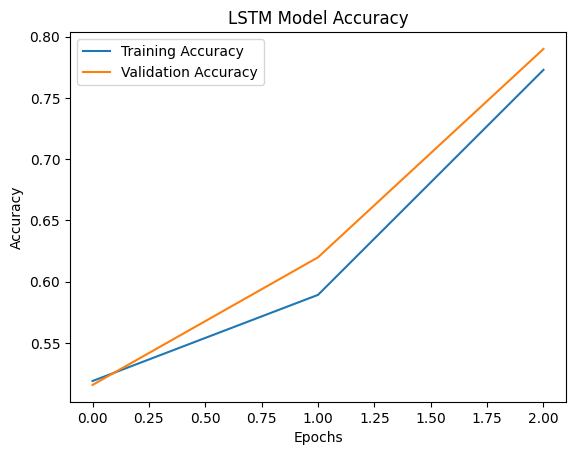

In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense
vocab_size = 10000

(X_train, y_train), (X_test, y_test) = imdb.load_data(
    num_words=vocab_size
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
max_length = 200

X_train = pad_sequences(
    X_train,
    maxlen=max_length,
    padding='post',
    truncating='post'
)

X_test = pad_sequences(
    X_test,
    maxlen=max_length,
    padding='post',
    truncating='post'
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)
model = Sequential([
    Embedding(vocab_size, 64),
    LSTM(64),
    Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()
history = model.fit(
    X_train,
    y_train,
    epochs=3,
    batch_size=64,
    validation_split=0.2
)

loss, accuracy = model.evaluate(X_test, y_test)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy * 100, "%")
predictions = model.predict(X_test[:5])

for i, prediction in enumerate(predictions):
    sentiment = "Positive" if prediction[0] >= 0.5 else "Negative"

    print("Review", i + 1)
    print("Predicted Sentiment:", sentiment)
    print("Actual Sentiment:", "Positive" if y_test[i] == 1 else "Negative")
    print()
word_index = imdb.get_word_index()

def predict_review(text):
    words = text.lower().split()

    sequence = [
        word_index.get(word, 2) + 3
        for word in words
    ]

    sequence = pad_sequences(
        [sequence],
        maxlen=max_length,
        padding='post',
        truncating='post'
    )

    prediction = model.predict(sequence, verbose=0)[0][0]

    sentiment = "Positive" if prediction >= 0.5 else "Negative"

    print("Review:", text)
    print("Prediction Score:", round(float(prediction), 4))
    print("Sentiment:", sentiment)

predict_review("This movie is amazing and I really enjoyed it")
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("LSTM Model Accuracy")
plt.legend()
plt.show()